<a href="https://colab.research.google.com/github/eslakshmishrujana-art/-New-York-City-Airbnb-Open-Data-Linear-Regression-/blob/main/linear_regression_project2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv('/content/listings.csv.zip')
df.head()

/tmp/ipykernel_914/3529229472.py:1: DtypeWarning: Columns (61,62,94,95) have mixed types. Specify dtype option on import or set low_memory=False.
  df=pd.read_csv('/content/listings.csv.zip')


,id,listing_url,scrape_id,last_scraped,name,summary,space,description,experiences_offered,neighborhood_overview,...,instant_bookable,is_business_travel_ready,cancellation_policy,require_guest_profile_picture,require_guest_phone_verification,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,2595,https://www.airbnb.com/rooms/2595,20190806030549,2019-08-07,Skylit Midtown Castle,"Find your romantic getaway to this beautiful, ...","- Spacious (500+ft²), immaculate and nicely fu...","Find your romantic getaway to this beautiful, ...",none,Centrally located in the heart of Manhattan ju...,...,f,f,strict_14_with_grace_period,t,t,2,1,0,1,0.39
1,3647,https://www.airbnb.com/rooms/3647,20190806030549,2019-08-06,THE VILLAGE OF HARLEM....NEW YORK !,NaN,WELCOME TO OUR INTERNATIONAL URBAN COMMUNITY T...,WELCOME TO OUR INTERNATIONAL URBAN COMMUNITY T...,none,NaN,...,f,f,strict_14_with_grace_period,t,t,1,0,1,0,NaN
2,3831,https://www.airbnb.com/rooms/3831,20190806030549,2019-08-06,Cozy Entire Floor of Brownstone,Urban retreat: enjoy 500 s.f. floor in 1899 br...,Greetings! We own a double-duplex brownst...,Urban retreat: enjoy 500 s.f. floor in 1899 br...,none,Just the right mix of urban center and local n...,...,f,f,moderate,f,f,1,1,0,0,4.64
3,5022,https://www.airbnb.com/rooms/5022,20190806030549,2019-08-06,Entire Apt: Spacious Studio/Loft by central park,NaN,Loft apartment with high ceiling and wood floo...,Loft apartment with high ceiling and wood floo...,none,NaN,...,f,f,strict_14_with_grace_period,t,t,1,1,0,0,0.10
4,5099,https://www.airbnb.com/rooms/5099,20190806030549,2019-08-06,Large Cozy 1 BR Apartment In Midtown East,My large 1 bedroom apartment is true New York ...,I have a large 1 bedroom apartment centrally l...,My large 1 bedroom apartment is true New York ...,none,My neighborhood in Midtown East is called Murr...,...,f,f,strict_14_with_grace_period,t,t,1,1,0,0,0.60


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48864 entries, 0 to 48863
Columns: 106 entries, id to reviews_per_month
dtypes: float64(22), int64(21), object(63)
memory usage: 39.5+ MB


In [ ]:
df.isnull().sum()

,0
id,0
listing_url,0
scrape_id,0
last_scraped,0
name,16
...,...
calculated_host_listings_count,0
calculated_host_listings_count_entire_homes,0
calculated_host_listings_count_private_rooms,0
calculated_host_listings_count_shared_rooms,0


In [ ]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage)

id                                               0.000000
listing_url                                      0.000000
scrape_id                                        0.000000
last_scraped                                     0.000000
name                                             0.032744
                                                  ...    
calculated_host_listings_count                   0.000000
calculated_host_listings_count_entire_homes      0.000000
calculated_host_listings_count_private_rooms     0.000000
calculated_host_listings_count_shared_rooms      0.000000
reviews_per_month                               20.733055
Length: 106, dtype: float64


In [ ]:
'last_review' in df.columns

True

In [ ]:
df.drop('last_review', axis=1, inplace=True)

In [ ]:
df['reviews_per_month'].isnull().sum()

np.int64(10131)

In [ ]:
# check no of reviews for missing rows
df.loc[df['reviews_per_month'].isnull(),
       'number_of_reviews'].value_counts()

,count
number_of_reviews,
0,10131


In [ ]:
# Replace missing values with 0
df['reviews_per_month'].fillna(0, inplace=True)

/tmp/ipykernel_914/4001338663.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['reviews_per_month'].fillna(0, inplace=True)


In [ ]:
df.drop(['id', 'name', 'host_name',
         'host_id', 'license'],
        axis=1, inplace=True, errors='ignore')

In [ ]:
print(df.isnull().sum())

listing_url                                         0
scrape_id                                           0
last_scraped                                        0
summary                                          2075
space                                           13985
                                                ...  
calculated_host_listings_count                      0
calculated_host_listings_count_entire_homes         0
calculated_host_listings_count_private_rooms        0
calculated_host_listings_count_shared_rooms         0
reviews_per_month                                   0
Length: 100, dtype: int64


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48864 entries, 0 to 48863
Data columns (total 100 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   listing_url                                   48864 non-null  object 
 1   scrape_id                                     48864 non-null  int64  
 2   last_scraped                                  48864 non-null  object 
 3   summary                                       46789 non-null  object 
 4   space                                         34879 non-null  object 
 5   description                                   48021 non-null  object 
 6   experiences_offered                           48864 non-null  object 
 7   neighborhood_overview                         31567 non-null  object 
 8   notes                                         20170 non-null  object 
 9   transit                                       31889 non-null

Text(0.5, 1.0, 'Boxplot of Price')

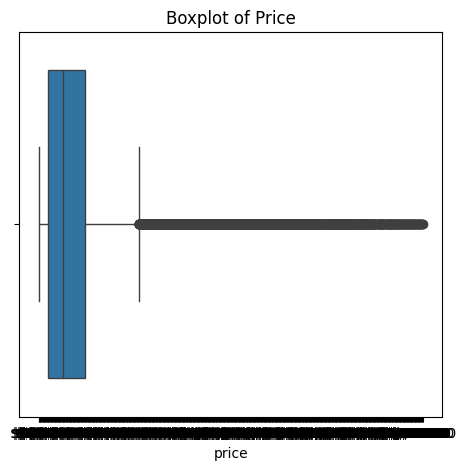

In [ ]:
plt.figure(figsize=(12,5))
# Price boxplot
plt.subplot(1,2,1)
sns.boxplot(x=df['price'])
plt.title('Boxplot of Price')

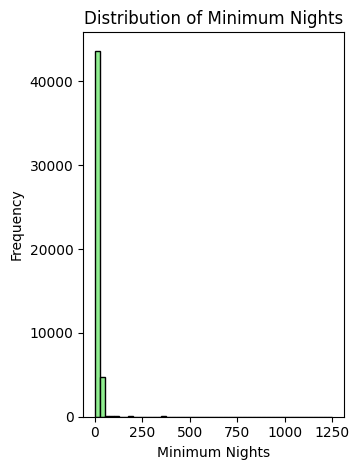

In [ ]:
# Minimum nights histogram
plt.subplot(1,2,2)
plt.hist(df['minimum_nights'], bins=50, color='lightgreen', edgecolor='black')
plt.title('Distribution of Minimum Nights')
plt.xlabel('Minimum Nights')
plt.ylabel('Frequency')

plt.tight_layout()
plt.show()

In [ ]:
# Clean the 'price' column: remove '$' and ',' then convert to float
if df['price'].dtype == 'object':
    df['price'] = df['price'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False)
    df['price'] = pd.to_numeric(df['price'], errors='coerce')

price_95 = df['price'].quantile(0.95)
min_nights_95 = df['minimum_nights'].quantile(0.95)

print("95th percentile of price:", price_95)
print("95th percentile of minimum_nights:", min_nights_95)

95th percentile of price: 350.0
95th percentile of minimum_nights: 30.0


In [ ]:
df_trimmed = df[
    (df['price'] <= price_95) &
    (df['minimum_nights'] <= min_nights_95)
]

print("Original shape:", df.shape)
print("Shape after removing outliers:", df_trimmed.shape)

Original shape: (48864, 100)
Shape after removing outliers: (45804, 100)


In [ ]:
'neighbourhood' in df.columns

True

In [ ]:
'neighbourhood_group' in df.columns

False

In [ ]:
'room_type' in df.columns

True

In [ ]:
#Encoding
df = pd.get_dummies(df, columns=['room_type'], drop_first=True)

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
# Task 5.1: features and target
X = df.drop(columns=["price"])
y = df["price"]
print(f"X shape: {X.shape}, y shape: {y.shape}")

# Task 5.2: 80/20 split with a fixed seed for reproducibility
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Train: {X_train.shape}, Test: {X_test.shape}")

X shape: (48864, 100), y shape: (48864,)
Train: (39091, 100), Test: (9773, 100)


In [ ]:
# Task 6.1: fit the model
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import numpy as np

# Select only numeric and boolean columns from the features
X_train_numeric = X_train.select_dtypes(include=[np.number, bool])
X_test_numeric = X_test.select_dtypes(include=[np.number, bool])
X_train_numeric = X_train_numeric.fillna(0)
X_test_numeric = X_test_numeric.fillna(0)

model = LinearRegression()
model.fit(X_train_numeric, y_train)

# Task 6.2: predict on the hidden test set
y_pred = model.predict(X_test_numeric)

# Task 6.3: metrics
r2   = r2_score(y_test, y_pred)
mae  = mean_absolute_error(y_test, y_pred)
mse  = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"R²   : {r2:.3f}  -> model explains {r2*100:.1f}% of price variance")
print(f"MAE  : ${mae:,.2f}  -> average miss in dollars")
print(f"MSE  : {mse:,.2f}")
print(f"RMSE : ${rmse:,.2f}  -> penalizes large misses more than MAE")

R²   : 0.157  -> model explains 15.7% of price variance
MAE  : $69.51  -> average miss in dollars
MSE  : 60,663.64
RMSE : $246.30  -> penalizes large misses more than MAE


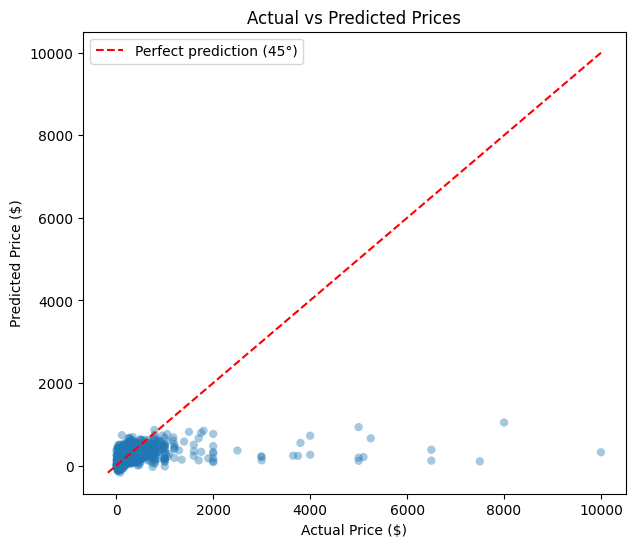

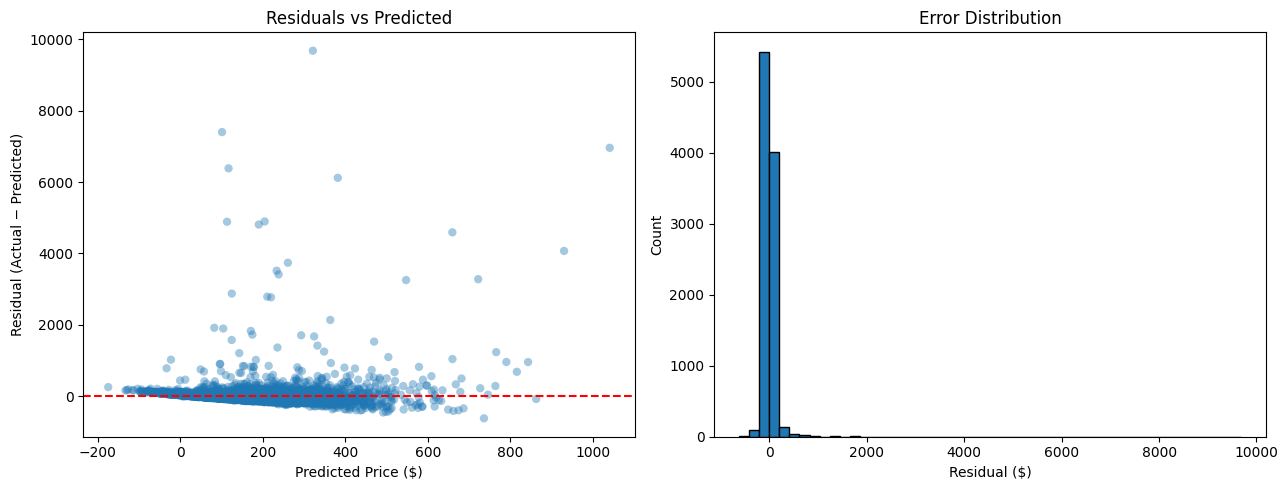

In [ ]:
residuals = y_test - y_pred

# Task 7.1: actual vs predicted with 45° line
plt.figure(figsize=(7, 6))
plt.scatter(y_test, y_pred, alpha=0.4, edgecolor="none")
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction (45°)")
plt.xlabel("Actual Price ($)"); plt.ylabel("Predicted Price ($)")
plt.title("Actual vs Predicted Prices"); plt.legend(); plt.show()

# Task 7.2: residual plot + error histogram
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_pred, residuals, alpha=0.4, edgecolor="none")
ax[0].axhline(0, color="r", linestyle="--")
ax[0].set(xlabel="Predicted Price ($)", ylabel="Residual (Actual − Predicted)",
          title="Residuals vs Predicted")
ax[1].hist(residuals, bins=50, edgecolor="black")
ax[1].set(xlabel="Residual ($)", ylabel="Count", title="Error Distribution")
plt.tight_layout(); plt.show()

In [ ]:
results = pd.DataFrame({"actual": y_test, "pred": y_pred})
results["abs_err"] = (results.actual - results.pred).abs()
results["pct_err"] = results.abs_err / results.actual * 100
results["price_tier"] = pd.qcut(results.actual, 4,
                                labels=["Cheap", "Mid-low", "Mid-high", "Expensive"])

summary = results.groupby("price_tier", observed=True).agg(
    MAE=("abs_err", "mean"),
    MAPE_pct=("pct_err", "mean"),
    mean_bias=("pred", "mean"),
    mean_actual=("actual", "mean"),
)
print(summary.round(2))

               MAE  MAPE_pct  mean_bias  mean_actual
price_tier                                          
Cheap        45.69       inf      74.48        50.31
Mid-low      46.66     54.10     113.87        86.84
Mid-high     49.91     36.42     166.33       139.67
Expensive   135.96     28.74     248.20       340.07
